# Machine Learning Project
## Part C: Text Classification

**Dataset:** IMDb Movie Reviews

**Dataset Source:** Zenodo

**Number of Reviews:** 50,000

**Classes:**
- Positive
- Negative

**Models:**
- Logistic Regression
- Linear Support Vector Machine (Linear SVM)

**Bonus:**
- Voting Classifier (Ensemble Learning)

# Part C: Text Classification

## 1. Importing Libraries

In [ ]:
import os
import re
import nltk
import joblib
import pandas as pd
import numpy as np

from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from scipy.sparse import save_npz


## 2. Loading the Dataset


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv(
    '/content/drive/MyDrive/DataSets/Text Dataset/IMDB Dataset.csv',
    engine='python',
    on_bad_lines='warn'
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (50000, 2)


## 3. Exploratory Data Analysis


In [ ]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (50000, 2)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
review       0
sentiment    0
dtype: int64


In [ ]:
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 418


## 4. Data Cleaning


In [ ]:
df_clean = df.drop_duplicates().copy()

In [ ]:
print("Shape after removing duplicates:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

Shape after removing duplicates: (49582, 2)
Remaining duplicates: 0


In [ ]:
print("Sentiment Distribution:")
print(df_clean['sentiment'].value_counts())

Sentiment Distribution:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


## 5. Text Preprocessing


In [ ]:
print("Original Review:")
print(df_clean['review'].iloc[0])

Original Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show 

In [ ]:
df_clean['review'] = df_clean['review'].str.lower()

In [ ]:
contractions = {
    "won't": "will not",
    "can't": "cannot",
    "n't": " not"
}

for contraction, replacement in contractions.items():
    if contraction == "n't":
        df_clean['review'] = df_clean['review'].str.replace(
            r"n't\b", replacement, regex=True
        )
    else:
        df_clean['review'] = df_clean['review'].str.replace(
            contraction, replacement, regex=False
        )

In [ ]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
df_clean['review'] = df_clean['review'].apply(
    lambda x: re.sub(r'<.*?>', ' ', x)
)

In [ ]:
df_clean['review'] = df_clean['review'].apply(
    lambda x: re.sub(r'[^\w\s]', ' ', x)
)

In [ ]:
df_clean['review'] = df_clean['review'].apply(
    lambda x: re.sub(r'\d+', ' ', x)
)

In [ ]:
stop_words = set(stopwords.words('english'))

negations = {'not', 'no', 'nor'}

stop_words = stop_words - negations

In [ ]:
df_clean['review'] = df_clean['review'].apply(
    lambda x: ' '.join(
        word for word in x.split()
        if word not in stop_words
    )
)

In [ ]:
df_clean['review'] = df_clean['review'].apply(
    lambda x: re.sub(r'\s+', ' ', x).strip()
)

In [ ]:
print("Cleaned Review:")
print(df_clean['review'].iloc[0])

display(df_clean.head())

Cleaned Review:
one reviewers mentioned watching oz episode hooked right exactly happened first thing struck oz brutality unflinching scenes violence set right word go trust not show faint hearted timid show pulls no punches regards drugs sex violence hardcore classic use word called oz nickname given oswald maximum security state penitentary focuses mainly emerald city experimental section prison cells glass fronts face inwards privacy not high agenda em city home many aryans muslims gangstas latinos christians italians irish scuffles death stares dodgy dealings shady agreements never far away would say main appeal show due fact goes shows would not dare forget pretty pictures painted mainstream audiences forget charm forget romance oz not mess around first episode ever saw struck nasty surreal could not say ready watched developed taste oz got accustomed high levels graphic violence not violence injustice crooked guards sold nickel inmates kill order get away well mannered middle cla

,review,sentiment
0,one reviewers mentioned watching oz episode ho...,positive
1,wonderful little production filming technique ...,positive
2,thought wonderful way spend time hot summer we...,positive
3,basically family little boy jake thinks zombie...,negative
4,petter mattei love time money visually stunnin...,positive


In [ ]:
print(df_clean.columns.tolist())

['review', 'sentiment']


In [ ]:
# Calculate the number of words in each review
df_clean['review_length'] = df_clean['review'].apply(lambda x: len(x.split()))

# Display basic statistics
print("Review Length Statistics:")
print(df_clean['review_length'].describe())

Review Length Statistics:
count    49582.000000
mean       121.412206
std         91.411799
min          3.000000
25%         65.000000
50%         90.000000
75%        148.000000
max       1436.000000
Name: review_length, dtype: float64


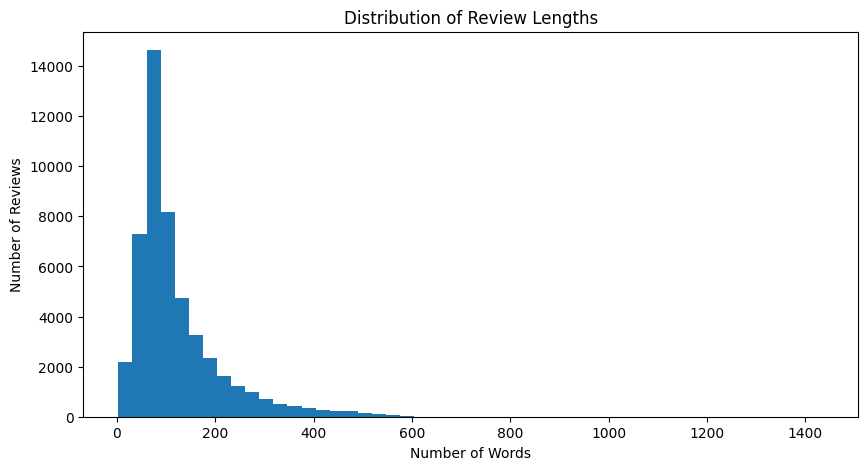

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df_clean['review_length'], bins=50)

plt.title('Distribution of Review Lengths')
plt.xlabel('Number of Words')
plt.ylabel('Number of Reviews')

plt.show()

Average Review Length per Sentiment:
sentiment
negative    120.101506
positive    122.713109
Name: review_length, dtype: float64


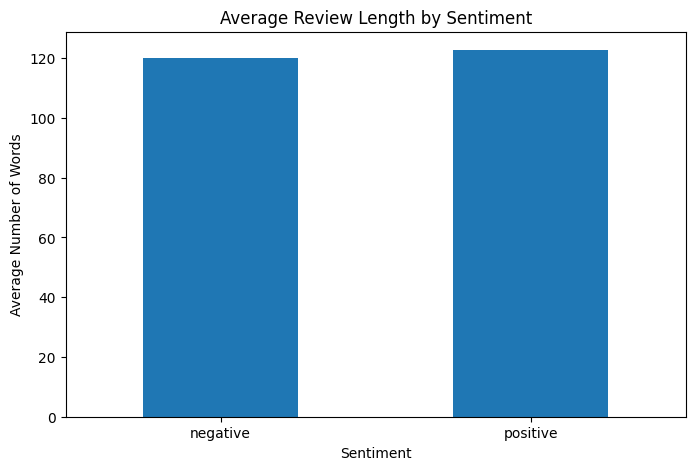

In [ ]:
# Calculate average review length for each sentiment
avg_length = df_clean.groupby('sentiment')['review_length'].mean()

print("Average Review Length per Sentiment:")
print(avg_length)

# Visualize average review length
plt.figure(figsize=(8, 5))

avg_length.plot(kind='bar')

plt.title('Average Review Length by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Average Number of Words')
plt.xticks(rotation=0)

plt.show()

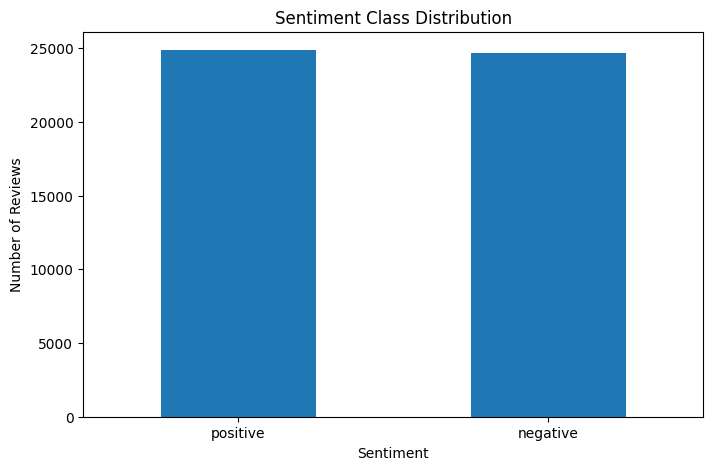

In [ ]:
# Visualize sentiment class distribution
sentiment_counts = df_clean['sentiment'].value_counts()

plt.figure(figsize=(8, 5))

sentiment_counts.plot(kind='bar')

plt.title('Sentiment Class Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)

plt.show()

## 6. Checking Preprocessed Data


In [ ]:
empty_reviews = (df_clean['review'].str.strip() == '').sum()

print("Empty Reviews:", empty_reviews)

Empty Reviews: 0


In [ ]:
print("Final Sentiment Distribution:")
print(df_clean['sentiment'].value_counts())

print("\nSentiment Percentages:")
print(df_clean['sentiment'].value_counts(normalize=True) * 100)

Final Sentiment Distribution:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64

Sentiment Percentages:
sentiment
positive    50.187568
negative    49.812432
Name: proportion, dtype: float64


## 7. Feature Extraction Using TF-IDF

In [ ]:
tfidf = TfidfVectorizer()

X = df_clean['review']
y = df_clean['sentiment']

## 8. Splitting the Dataset


In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [ ]:
print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Testing Set:", X_test.shape)

print("\nTraining Distribution:")
print(y_train.value_counts())

print("\nValidation Distribution:")
print(y_val.value_counts())

print("\nTesting Distribution:")
print(y_test.value_counts())

Training Set: (34707,)
Validation Set: (7437,)
Testing Set: (7438,)

Training Distribution:
sentiment
positive    17419
negative    17288
Name: count, dtype: int64

Validation Distribution:
sentiment
positive    3732
negative    3705
Name: count, dtype: int64

Testing Distribution:
sentiment
positive    3733
negative    3705
Name: count, dtype: int64


## 9. Applying TF-IDF Transformation


In [ ]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_val_tfidf = tfidf.transform(X_val)

X_test_tfidf = tfidf.transform(X_test)

In [ ]:
print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Validation TF-IDF Shape:", X_val_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

print("Vocabulary Size:", len(tfidf.vocabulary_))

Training TF-IDF Shape: (34707, 86316)
Validation TF-IDF Shape: (7437, 86316)
Testing TF-IDF Shape: (7438, 86316)
Vocabulary Size: 86316


## 10. Saving Preprocessed Data


In [ ]:
output_dir = '/content/drive/MyDrive/DataSets/Text Dataset/Preprocessed Data'

os.makedirs(output_dir, exist_ok=True)

In [ ]:
save_npz(
    output_dir + '/X_train_tfidf.npz',
    X_train_tfidf
)

save_npz(
    output_dir + '/X_val_tfidf.npz',
    X_val_tfidf
)

save_npz(
    output_dir + '/X_test_tfidf.npz',
    X_test_tfidf
)

In [ ]:
joblib.dump(
    tfidf,
    output_dir + '/tfidf_vectorizer.joblib'
)

['/content/drive/MyDrive/DataSets/Text Dataset/Preprocessed Data/tfidf_vectorizer.joblib']

In [ ]:
df_clean.to_csv(
    output_dir + '/cleaned_dataset.csv',
    index=False
)

In [ ]:
y_train.to_csv(
    output_dir + '/y_train.csv',
    index=False,
    header=['sentiment']
)

y_val.to_csv(
    output_dir + '/y_val.csv',
    index=False,
    header=['sentiment']
)

y_test.to_csv(
    output_dir + '/y_test.csv',
    index=False,
    header=['sentiment']
)

In [ ]:
print("Saved Files:")

for file in os.listdir(output_dir):
    print(file)

Saved Files:
X_train_tfidf.npz
cleaned_dataset.csv
X_test_tfidf.npz
X_val_tfidf.npz
tfidf_vectorizer.joblib
y_val.csv
y_test.csv
y_train.csv
